In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

drive_path = "/content/drive/MyDrive/SignVisionAI"

print(os.listdir(drive_path))

['archive (1).zip']


In [3]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/SignVisionAI/archive (1).zip"
extract_path = "/content/asl_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset successfully extracted!")

print(os.listdir(extract_path))

Dataset successfully extracted!
['asl_alphabet_train', 'asl_alphabet_test']


In [4]:

import os

base_path = "/content/asl_dataset"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        if level >= 3:
            dirs[:] = []


asl_dataset/
  asl_alphabet_train/
    asl_alphabet_train/
      N/
      O/
      L/
      G/
      H/
      del/
      T/
      M/
      R/
      C/
      nothing/
      A/
      X/
      V/
      I/
      Q/
      B/
      S/
      U/
      K/
      P/
      J/
      E/
      F/
      W/
      Z/
      space/
      Y/
      D/
  asl_alphabet_test/
    asl_alphabet_test/


In [5]:

import os

data_path = "/content/asl_dataset/asl_alphabet_train/asl_alphabet_train"

classes = sorted(os.listdir(data_path))

print("Total classes:", len(classes))
print("Class names:", classes)

for class_name in classes:
    folder_path = os.path.join(data_path, class_name)
    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(class_name, "=", len(images), "images")


Total classes: 29
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
A = 3000 images
B = 3000 images
C = 3000 images
D = 3000 images
E = 3000 images
F = 3000 images
G = 3000 images
H = 3000 images
I = 3000 images
J = 3000 images
K = 3000 images
L = 3000 images
M = 3000 images
N = 3000 images
O = 3000 images
P = 3000 images
Q = 3000 images
R = 3000 images
S = 3000 images
T = 3000 images
U = 3000 images
V = 3000 images
W = 3000 images
X = 3000 images
Y = 3000 images
Z = 3000 images
del = 3000 images
nothing = 3000 images
space = 3000 images


In [6]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:

import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:

import tensorflow as tf

data_path = "/content/asl_dataset/asl_alphabet_train/asl_alphabet_train"

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Total classes:", len(class_names))
print("Class names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


Found 87000 files belonging to 29 classes.
Using 69600 files for training.
Found 87000 files belonging to 29 classes.
Using 17400 files for validation.
Total classes: 29
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [9]:

import os
import tensorflow as tf

data_path = "/content/asl_dataset/asl_alphabet_train/asl_alphabet_train"

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Dataset path exists:", os.path.exists(data_path))

if os.path.exists(data_path):
    print("Classes:", len(os.listdir(data_path)))
    print("Sample classes:", sorted(os.listdir(data_path))[:5])


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset path exists: True
Classes: 29
Sample classes: ['A', 'B', 'C', 'D', 'E']


In [10]:

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Total classes:", len(class_names))
print("Training aur validation datasets ready!")


Found 87000 files belonging to 29 classes.
Using 69600 files for training.
Found 87000 files belonging to 29 classes.
Using 17400 files for validation.
Total classes: 29
Training aur validation datasets ready!


In [11]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Pehle se trained layers ko freeze karein
base_model.trainable = False

# Apna SignVision AI classifier
inputs = layers.Input(shape=(160, 160, 3))

x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 29)             │        37,149 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,295,133 (8.76 MB)

 Trainable params: 37,149 (145.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=2,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)


Epoch 1/8
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 56s 26ms/step - accuracy: 0.9871 - loss: 0.0391 - val_accuracy: 0.9953 - val_loss: 0.0162
Epoch 2/8
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 82s 26ms/step - accuracy: 0.9889 - loss: 0.0338 - val_accuracy: 0.9956 - val_loss: 0.0149
Epoch 3/8
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 56s 26ms/step - accuracy: 0.9888 - loss: 0.0334 - val_accuracy: 0.9974 - val_loss: 0.0115
Epoch 4/8
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 82s 26ms/step - accuracy: 0.9893 - loss: 0.0320 - val_accuracy: 0.9966 - val_loss: 0.0124
Epoch 5/8
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 65s 30ms/step - accuracy: 0.9902 - loss: 0.0293 - val_accuracy: 0.9968 - val_loss: 0.0114


In [14]:

import os
import json

# Google Drive mein project folder
save_dir = "/content/drive/MyDrive/SignVisionAI"
os.makedirs(save_dir, exist_ok=True)

# Trained model save karein
model_path = os.path.join(save_dir, "signvision_model.keras")
model.save(model_path)

# Class names save karein
labels_path = os.path.join(save_dir, "class_names.json")

with open(labels_path, "w") as f:
    json.dump(class_names, f)

# Training history save karein
history_path = os.path.join(save_dir, "training_history.json")

with open(history_path, "w") as f:
    json.dump(
        {key: [float(v) for v in values]
         for key, values in history.history.items()},
        f,
        indent=2
    )

print("Model saved:", model_path)
print("Labels saved:", labels_path)
print("Training history saved:", history_path)


Model saved: /content/drive/MyDrive/SignVisionAI/signvision_model.keras
Labels saved: /content/drive/MyDrive/SignVisionAI/class_names.json
Training history saved: /content/drive/MyDrive/SignVisionAI/training_history.json


In [15]:

loss, accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")


544/544 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9974 - loss: 0.0115
Validation Loss: 0.0115
Validation Accuracy: 99.74%


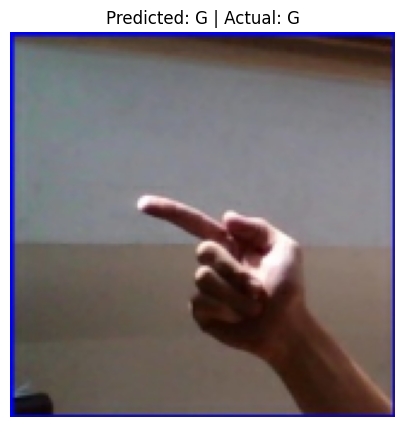

Predicted class: G
Actual class: G
Prediction confidence: 100.00%


In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Validation dataset se ek batch lein
images, labels = next(iter(val_ds))

# Pehli image par prediction
predictions = model.predict(images[:1], verbose=0)

predicted_index = np.argmax(predictions[0])
actual_index = int(labels[0])

predicted_letter = class_names[predicted_index]
actual_letter = class_names[actual_index]
confidence = float(predictions[0][predicted_index]) * 100

# Image aur results show karein
plt.figure(figsize=(5, 5))
plt.imshow(images[0].numpy().astype("uint8"))
plt.axis("off")
plt.title(
    f"Predicted: {predicted_letter} | Actual: {actual_letter}"
)
plt.show()

print("Predicted class:", predicted_letter)
print("Actual class:", actual_letter)
print(f"Prediction confidence: {confidence:.2f}%")


In [17]:

import os

model_path = "/content/drive/MyDrive/SignVisionAI/signvision_model.keras"

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print(f"Model size: {size_mb:.2f} MB")
print("Model file exists:", os.path.exists(model_path))


Model size: 9.60 MB
Model file exists: True
